<a href="https://colab.research.google.com/github/dhanusratnam22/CMPE401-YOLO11-VisDrone/blob/main/CMPE401_Project1_YOLO11_VisDrone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: NVIDIA A100-SXM4-80GB


In [3]:
import os
baseline_path = "/content/drive/MyDrive/CMPE401_Project1_25Epoch/runs/baseline_yolo11n_640_25ep/weights/best.pt"
experiment_path = "/content/drive/MyDrive/CMPE401_Project1_25Epoch/runs/experiment_yolo11n_800_25ep/weights/best.pt"
print("640 model exists:", os.path.exists(baseline_path))
print("800 model exists:", os.path.exists(experiment_path))

640 model exists: True
800 model exists: True


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os
PROJECT_DIR = "/content/drive/MyDrive/CMPE401_Project1_25Epoch"
os.makedirs(PROJECT_DIR, exist_ok=True)
print("Project directory:", PROJECT_DIR)

Project directory: /content/drive/MyDrive/CMPE401_Project1_25Epoch


In [6]:
!pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 75.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [7]:
from ultralytics import YOLO
import ultralytics
ultralytics.checks()

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (8 CPUs, 51.0 GB RAM, 0.1/235.7 GB disk)


# Part I – Baseline Model

In [ ]:
baseline_model = YOLO("yolo11n.pt")
baseline_results = baseline_model.train(
    data="VisDrone.yaml",
    epochs=25,
    imgsz=640,
    batch=8,
    seed=0,
    deterministic=True,
    project=PROJECT_DIR + "/runs",
    name="baseline_yolo11n_640_25ep"
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VisDrone.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolo11n_640_25ep, nbs=64, nms=None, opset=None, optimi

In [8]:
BASELINE_DIR = PROJECT_DIR + "/runs/baseline_yolo11n_640_25ep"
baseline_best = YOLO(BASELINE_DIR + "/weights/best.pt")
baseline_val = baseline_best.val(
    data="VisDrone.yaml",
    imgsz=640,
    batch=8,
    max_det=902,
    plots=True
)
print("\nBASELINE RESULTS")
print("Precision:", baseline_val.box.mp)
print("Recall:", baseline_val.box.mr)
print("mAP50:", baseline_val.box.map50)
print("mAP50-95:", baseline_val.box.map)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs

WARNING ⚠️ Dataset 'VisDrone.yaml' images not found, missing path '/content/datasets/VisDrone/images/val'
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-val.zip to /content/datasets/VisDrone/VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 1.8Kfiles/s 0.6s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-test-dev.zip to /content/datasets/VisDrone/VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 1.6Kfiles/s 2.0s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-train.zip to /content/datasets/VisDrone/VisDrone2019-DET-train...: 100% ━━━━━━━━━━━━ 12945/12945 2.1Kfiles/s 6.2s
Converting train: ━━━━━━━━━━━━ 6471 2.5Kit/s 2.8s
Converting val: ━━━━━━━━━━━━ 548 1.5Kit/s 0.2s
Converting test: ━━━━━━━━━━━━ 1610 2.3Kit/s 0.6s
Dataset download success ✅ (20.2s), saved to /content/datasets

val: Fast imag

# Part II – Loss Curve and Fitting Analysis

In [ ]:
import pandas as pd
baseline_csv = BASELINE_DIR + "/results.csv"
baseline_df = pd.read_csv(baseline_csv)
# Remove extra spaces from column names
baseline_df.columns = baseline_df.columns.str.strip()
baseline_df.head()


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,74.688,1.87141,1.84325,1.01728,0.27937,0.21311,0.17263,0.09145,1.72146,1.36275,0.95029,0.000238,0.000238,0.000238
1,2,141.010,1.79861,1.43031,0.96525,0.28810,0.23485,0.18321,0.09872,1.71546,1.38397,0.95135,0.000457,0.000457,0.000457
2,3,207.534,1.79030,1.37920,0.95621,0.30693,0.24501,0.20312,0.10759,1.67620,1.27380,0.92897,0.000657,0.000657,0.000657
3,4,273.559,1.76332,1.34418,0.94693,0.33964,0.24375,0.21289,0.11479,1.67951,1.26462,0.92928,0.000629,0.000629,0.000629
4,5,339.476,1.73503,1.31120,0.94140,0.34336,0.26622,0.23119,0.12354,1.62134,1.21684,0.92355,0.000601,0.000601,0.000601


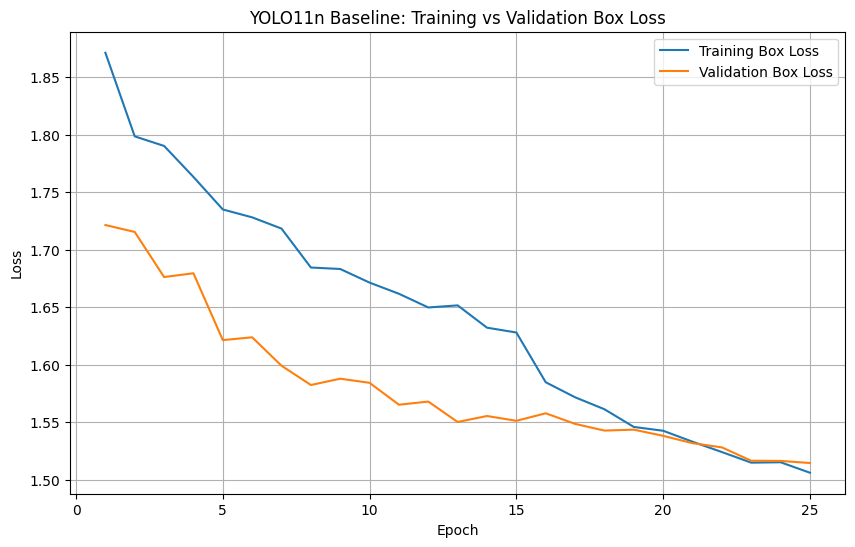

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(
    baseline_df["epoch"],
    baseline_df["train/box_loss"],
    label="Training Box Loss"
)
plt.plot(
    baseline_df["epoch"],
    baseline_df["val/box_loss"],
    label="Validation Box Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLO11n Baseline: Training vs Validation Box Loss")
plt.legend()
plt.grid()
plt.show()

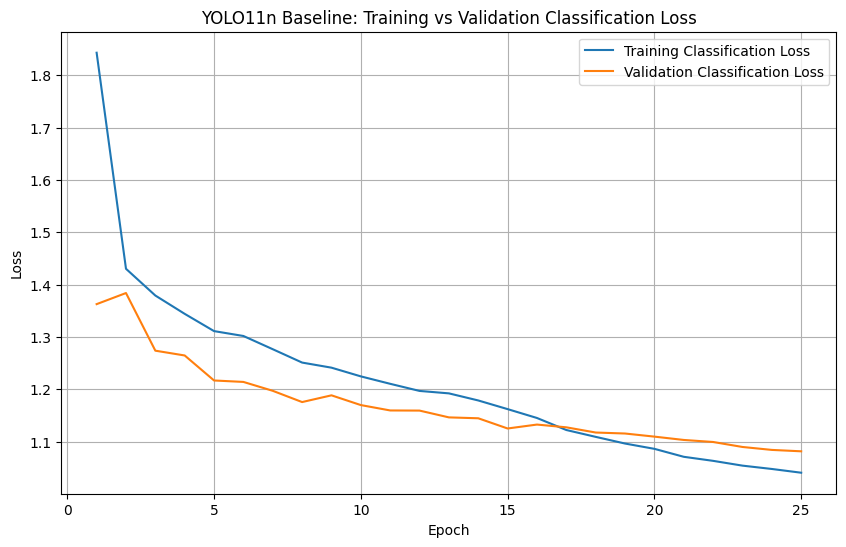

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(
    baseline_df["epoch"],
    baseline_df["train/cls_loss"],
    label="Training Classification Loss"
)
plt.plot(
    baseline_df["epoch"],
    baseline_df["val/cls_loss"],
    label="Validation Classification Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLO11n Baseline: Training vs Validation Classification Loss")
plt.legend()
plt.grid()
plt.show()

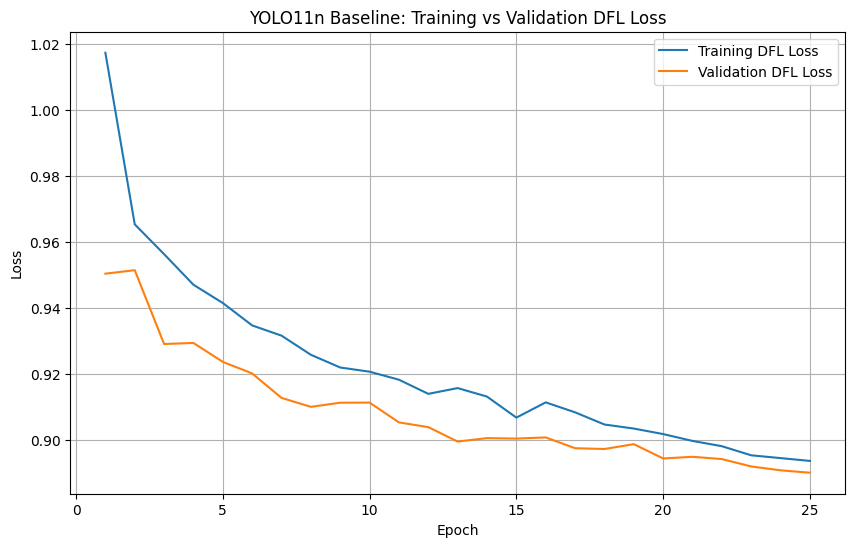

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    baseline_df["epoch"],
    baseline_df["train/dfl_loss"],
    label="Training DFL Loss"
)

plt.plot(
    baseline_df["epoch"],
    baseline_df["val/dfl_loss"],
    label="Validation DFL Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLO11n Baseline: Training vs Validation DFL Loss")
plt.legend()
plt.grid()

plt.show()

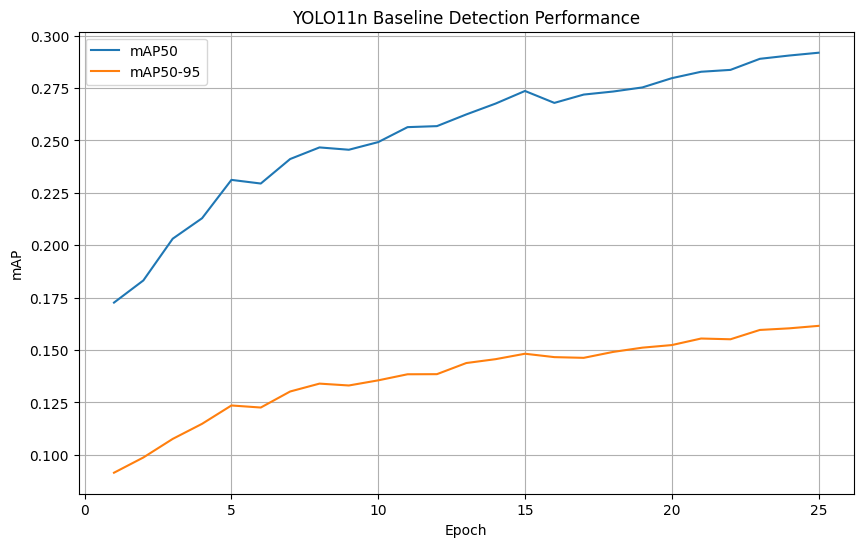

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    baseline_df["epoch"],
    baseline_df["metrics/mAP50(B)"],
    label="mAP50"
)

plt.plot(
    baseline_df["epoch"],
    baseline_df["metrics/mAP50-95(B)"],
    label="mAP50-95"
)

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("YOLO11n Baseline Detection Performance")
plt.legend()
plt.grid()

plt.show()

### Fitting Analysis

The training and validation loss curves both decreased over the 25 epochs, showing that the YOLO11n model was learning and moving towards convergence. The box loss, classification loss and DFL loss all showed an overall downward trend. The validation losses followed a similar pattern to the training losses rather than increasing sharply.

There is no clear evidence of severe overfitting in this experiment. Overfitting would normally occur if the training loss continued to decrease while the validation loss started to increase or validation performance became worse. This pattern was not strongly observed here. Instead, both training and validation performance generally improved together.

There is also no strong evidence of severe underfitting because the losses decreased consistently and the mAP values improved throughout training. However, the mAP curves were still increasing near epoch 25, which suggests that the model may not have reached its full convergence point. Training for additional epochs could potentially improve performance further.

The VisDrone dataset used for this experiment contains 6,471 training images and 548 validation images. It is a challenging object-detection dataset because many images contain dense scenes and small objects such as pedestrians, bicycles and vehicles. This increases the difficulty of the detection task.

YOLO11n is the nano version of YOLO11 and has relatively low model capacity compared with larger YOLO11 variants. Its smaller capacity makes it computationally efficient, but it may limit its ability to learn complex features from dense scenes. Overall, the results indicate that the baseline model learned meaningful features without obvious overfitting, although additional training or increased model capacity could potentially improve performance.

# Part III – Structured Experimental Design

A controlled experiment was conducted to evaluate whether increasing the input image resolution could improve object detection performance on the VisDrone dataset.

The baseline model used YOLO11n with an image resolution of 640 × 640. The experimental model used the same YOLO11n architecture, dataset, batch size, number of epochs, random seed and training settings, but increased the image resolution to 800 × 800.

### Experimental Settings

- Model: YOLO11n
- Dataset: VisDrone
- Baseline resolution: 640 × 640
- Experimental resolution: 800 × 800
- Epochs: 25
- Batch size: 8
- Seed: 0

### Hypothesis

Increasing the input resolution may improve detection performance because VisDrone contains many small and densely packed objects. A higher resolution preserves more spatial detail, which may help the model detect pedestrians, vehicles and other small objects more accurately.

In [ ]:
experiment_model = YOLO("yolo11n.pt")
experiment_results = experiment_model.train(
    data="VisDrone.yaml",
    epochs=25,
    imgsz=800,
    batch=8,
    seed=0,
    deterministic=True,
    project=PROJECT_DIR + "/runs",
    name="experiment_yolo11n_800_25ep"
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VisDrone.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment_yolo11n_800_25ep, nbs=64, nms=None, opset=None, opti

In [11]:
EXPERIMENT_DIR = PROJECT_DIR + "/runs/experiment_yolo11n_800_25ep"
experiment_best = YOLO(EXPERIMENT_DIR + "/weights/best.pt")
experiment_val = experiment_best.val(
    data="VisDrone.yaml",
    imgsz=800,
    batch=8,
    max_det=902,
    plots=True
)
print("\n800 RESOLUTION RESULTS")
print("Precision:", experiment_val.box.mp)
print("Recall:", experiment_val.box.mr)
print("mAP50:", experiment_val.box.map50)
print("mAP50-95:", experiment_val.box.map)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3514.0±671.0 MB/s, size: 131.6 KB)
val: Scanning /content/datasets/VisDrone/labels/val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 143.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 10.1it/s 6.9s
                   all        548      38759      0.479      0.357      0.356      0.203
            pedestrian        520       8844      0.476      0.391       0.38      0.163
                people        482       5125      0.525      0.264      0.292      0.102
               bicycle        364       1287      0.272      0.131      0.116     0.0458
                   car        515      14064      0.657      0.772      0.766      0.517
                   van        421 

# Part IV – Iterative Model Improvement

In [13]:
import pandas as pd

baseline_metrics = {
    "Precision": float(baseline_val.box.mp),
    "Recall": float(baseline_val.box.mr),
    "mAP50": float(baseline_val.box.map50),
    "mAP50-95": float(baseline_val.box.map)
}
experiment_metrics = {
    "Precision": float(experiment_val.box.mp),
    "Recall": float(experiment_val.box.mr),
    "mAP50": float(experiment_val.box.map50),
    "mAP50-95": float(experiment_val.box.map)
}
comparison_df = pd.DataFrame({
    "Metric": baseline_metrics.keys(),
    "640 Baseline": baseline_metrics.values(),
    "800 Experiment": experiment_metrics.values()
})
comparison_df["Change"] = (
    comparison_df["800 Experiment"]
    - comparison_df["640 Baseline"]
)
comparison_df

,Metric,640 Baseline,800 Experiment,Change
0,Precision,0.407502,0.478727,0.071226
1,Recall,0.310555,0.357493,0.046938
2,mAP50,0.292383,0.355565,0.063182
3,mAP50-95,0.161858,0.202933,0.041075


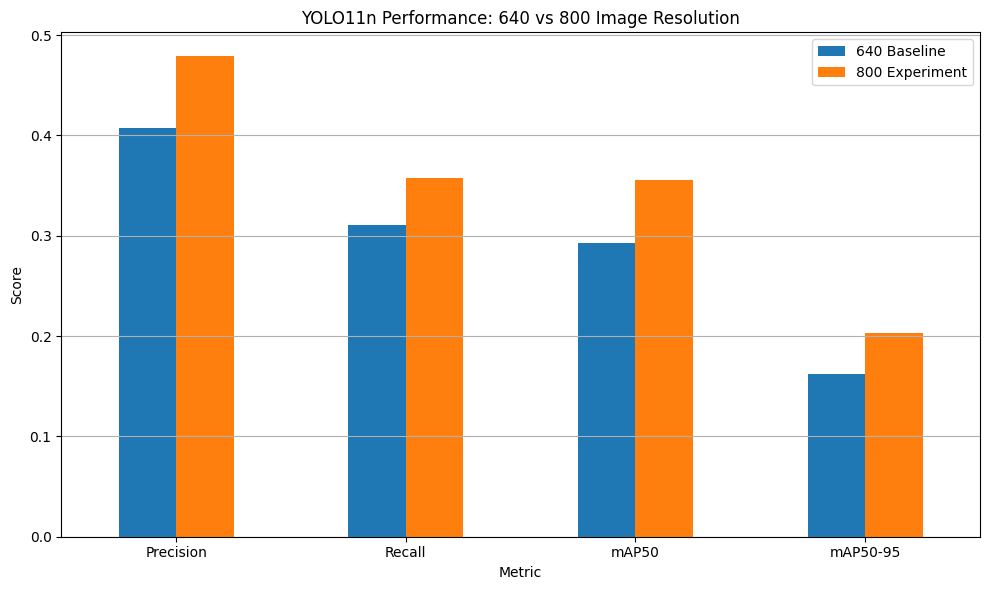

In [14]:
import matplotlib.pyplot as plt
comparison_plot = comparison_df.set_index("Metric")[
    ["640 Baseline", "800 Experiment"]
]
comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("YOLO11n Performance: 640 vs 800 Image Resolution")
plt.ylabel("Score")
plt.xlabel("Metric")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [15]:
if experiment_val.box.map > baseline_val.box.map:
    best_model = experiment_best
    best_resolution = 800
    print("Best model: 800-resolution experiment")
else:
    best_model = baseline_best
    best_resolution = 640
    print("Best model: 640-resolution baseline")

Best model: 800-resolution experiment


### Performance Analysis and Conclusion

The controlled modification in this experiment was an increase in input image resolution from 640 × 640 to 800 × 800 while keeping the YOLO11n architecture, dataset, batch size, number of epochs and random seed unchanged.

The 800 × 800 experiment achieved better overall detection performance than the 640 × 640 baseline. Precision, recall, mAP50 and mAP50–95 all increased, showing that the higher-resolution input improved the model's ability to detect objects in the VisDrone dataset.

The improvement is likely related to the large number of small and densely packed objects in VisDrone images. Increasing the image resolution preserves more spatial detail before the image is processed by the network. This gives YOLO11n more information for detecting small objects such as pedestrians, bicycles and vehicles.

However, increasing resolution also increases computational cost because the model must process more pixels for each image. Therefore, the improvement in detection accuracy comes with a trade-off in training and inference efficiency.

Overall, the experiment supports the original hypothesis that increasing input resolution can improve object detection performance on VisDrone. Based on the evaluation results, the 800 × 800 model was selected as the best-performing model for the final detection examples.

# Best Model Detection Examples

The best-performing model was evaluated on sample VisDrone validation images to assess its detection performance visually.

In [ ]:
import glob
val_images = sorted(
    glob.glob("/content/datasets/VisDrone/images/val/*")
)
sample_images = val_images[:6]
prediction_results = best_model.predict(
    source=sample_images,
    imgsz=best_resolution,
    conf=0.25,
    save=True,
    project=PROJECT_DIR + "/predictions",
    name="best_model_examples"
)
print("Detection examples saved.")


0: 480x800 3 pedestrians, 7 peoples, 14 cars, 1 truck, 4 tricycles, 3 awning-tricycles, 27 motors, 1.6ms
1: 480x800 3 pedestrians, 2 peoples, 18 cars, 1 van, 2 tricycles, 1 awning-tricycle, 7 motors, 1.6ms
2: 480x800 7 pedestrians, 9 peoples, 1 bicycle, 4 cars, 1 tricycle, 19 motors, 1.6ms
3: 480x800 6 pedestrians, 2 peoples, 2 bicycles, 2 cars, 2 vans, 1 tricycle, 4 awning-tricycles, 18 motors, 1.6ms
4: 480x800 7 pedestrians, 2 peoples, 86 cars, 4 vans, 1 truck, 1 tricycle, 6 motors, 1.6ms
5: 480x800 1 pedestrian, 1 people, 2 bicycles, 70 cars, 6 vans, 3 motors, 1.6ms
Speed: 2.5ms preprocess, 1.6ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 800)
Results saved to /content/drive/MyDrive/CMPE401_Project1_25Epoch/predictions/best_model_examples
Detection examples saved.


# Conclusion

This project developed and evaluated a YOLO11n object detection model using the VisDrone dataset. A baseline model was first trained using an input resolution of 640 × 640 for 25 epochs. The training and validation loss curves showed consistent learning without clear evidence of severe overfitting, although the model appeared capable of further improvement.

A controlled experiment was then performed by increasing the image resolution from 640 × 640 to 800 × 800 while keeping the remaining training settings unchanged. The higher-resolution model achieved better overall performance across precision, recall, mAP50 and mAP50–95. This indicates that preserving additional spatial detail was beneficial for detecting the small and densely distributed objects commonly found in VisDrone images.

The 800 × 800 model was therefore selected as the best-performing model and was used to generate final detection examples. The experiment demonstrates the importance of input resolution when designing object detection systems for datasets containing small objects. However, the improved accuracy also comes with increased computational requirements.

Overall, the project demonstrated a complete object detection workflow including baseline training, loss and fitting analysis, controlled experimentation, quantitative evaluation, iterative improvement and final model selection.